## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


In [3]:
# shutil.rmtree("/kaggle/working/cjpe_runs_fast")

## 4. Load Tokenizer

In [5]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 9. Define The Model

## LMConfig

In [6]:
@dataclass
class LMConfig:
    # ---- general ----
    vocab_size: int = VOCAB_SIZE
    max_seq_len: int = MODEL_CONTEXT_LENGTH
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    dropout: float = 0.0
    bias: bool = False
    tie_embeddings: bool = True
    norm_type: str = "rmsnorm"          # "rmsnorm" | "layernorm"
    norm_eps: float = 1e-6

    # ---- positional ----
    pos_emb_type: str = "rope"          # "rope" | "sinusoidal"
    rope_theta: float = 10000.0

    # ---- attention ----
    attn_type: str = "gqa"              # "gqa" | "mla"
    n_heads: int = N_HEAD
    # GQA (n_kv_heads == n_heads -> MHA, 1 -> MQA)
    n_kv_heads: int = 2
    head_dim: Optional[int] = None      # defaults to d_model // n_heads
    # MLA
    q_lora_rank: Optional[int] = 256    # None -> no query compression
    kv_lora_rank: int = 128
    qk_nope_head_dim: int = 48
    qk_rope_head_dim: int = 16
    v_head_dim: int = 64

    # ---- feed-forward ----
    ffn_type: str = "dense"             # "dense" | "moe"
    d_ff: int = 2048
    # MoE
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 1
    expert_d_ff: int = 512
    aux_loss_coef: float = 0.01
    first_k_dense_layers: int = 0       # first k layers stay dense
    moe_layer_freq: int = 1             # after that, every n-th layer is MoE

    def __post_init__(self):
        assert self.norm_type in ("rmsnorm", "layernorm")
        assert self.pos_emb_type in ("rope", "sinusoidal")
        assert self.attn_type in ("gqa", "mla")
        assert self.ffn_type in ("dense", "moe")

        if self.pos_emb_type == "sinusoidal":
            assert self.d_model % 2 == 0, "sinusoidal needs even d_model"

        if self.attn_type == "gqa":
            if self.head_dim is None:
                assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"
                self.head_dim = self.d_model // self.n_heads
            assert self.n_heads % self.n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
            if self.pos_emb_type == "rope":
                assert self.head_dim % 2 == 0, "RoPE needs even head_dim"
        else:
            if self.pos_emb_type == "rope":
                assert self.qk_rope_head_dim % 2 == 0 and self.qk_rope_head_dim > 0

        if self.ffn_type == "moe":
            assert 1 <= self.top_k <= self.n_experts

    @property
    def rope_dim(self) -> int:
        return self.qk_rope_head_dim if self.attn_type == "mla" else self.head_dim

    def is_moe_layer(self, layer_idx: int) -> bool:
        if self.ffn_type != "moe" or layer_idx < self.first_k_dense_layers:
            return False
        return (layer_idx - self.first_k_dense_layers) % self.moe_layer_freq == 0

## Normalization layers

In [7]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


def make_norm(cfg: LMConfig, dim: int) -> nn.Module:
    if cfg.norm_type == "rmsnorm":
        return RMSNorm(dim, cfg.norm_eps)
    return nn.LayerNorm(dim, eps=cfg.norm_eps)

## Positional embeddings (RoPE and sinusoidal)

In [8]:
class RoPE(nn.Module):
    """Rotary embedding. Rotates q and k of shape (B, H, T, dim)."""

    def __init__(self, dim: int, max_seq_len: int, theta: float = 10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.outer(t, inv_freq)               # (L, dim/2)
        emb = torch.cat([freqs, freqs], dim=-1)        # (L, dim)
        self.register_buffer("cos", emb.cos(), persistent=False)
        self.register_buffer("sin", emb.sin(), persistent=False)

    @staticmethod
    def _rotate_half(x):
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat([-x2, x1], dim=-1)

    def rotate(self, x, positions):
        cos, sin = self.cos[positions], self.sin[positions]
        if cos.dim() == 2:                              # positions: (T,)
            cos, sin = cos[None, None], sin[None, None]
        else:                                           # positions: (B, T)
            cos, sin = cos[:, None], sin[:, None]
        cos, sin = cos.to(x.dtype), sin.to(x.dtype)
        return x * cos + self._rotate_half(x) * sin

    def forward(self, q, k, positions):
        return self.rotate(q, positions), self.rotate(k, positions)


class SinusoidalPositionalEmbedding(nn.Module):
    """Fixed sin/cos table, added to token embeddings once at model level."""

    def __init__(self, d_model: int, max_seq_len: int):
        super().__init__()
        pos = torch.arange(max_seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x, offset: int = 0):
        T = x.size(1)
        return x + self.pe[offset:offset + T].to(x.dtype)

## Attention helper and GQA

In [9]:
def causal_sdpa(q, k, v, dropout_p: float = 0.0, training: bool = False):
    """Causal attention that also works when k/v are longer than q (KV cache)."""
    Tq, Tk = q.size(2), k.size(2)
    p = dropout_p if training else 0.0
    if Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
    if Tq == 1:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p)
    mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)


def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
    if attn_mask is None:
        return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
    return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                          dropout_p=dropout_p if training else 0.0)

class GQAttention(nn.Module):
    """Grouped-query attention. cache = (k, v), each (B, n_kv_heads, T, head_dim)."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.q_proj = nn.Linear(cfg.d_model, self.n_heads * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.o_proj = nn.Linear(self.n_heads * self.hd, cfg.d_model, bias=cfg.bias)
        self.dropout = cfg.dropout

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        if rope is not None:
            q, k = rope(q, k, positions)
        if kv_cache is not None:
            k = torch.cat([kv_cache[0], k], dim=2)
            v = torch.cat([kv_cache[1], v], dim=2)
        new_cache = (k, v)
        rep = self.n_heads // self.n_kv
        out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
                          attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
        return self.o_proj(out), new_cache

## MLA

In [10]:
class MLAttention(nn.Module):
    """
    Multi-head Latent Attention (DeepSeek-style, un-absorbed version).
    cache = (latent (B, 1, T, kv_lora_rank), k_rope (B, 1, T, rope_dim) or None).
    Only the compressed latent and the small shared k_rope are cached.
    With sinusoidal positions the decoupled RoPE part is dropped (rope_dim = 0).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.H = cfg.n_heads
        self.dn = cfg.qk_nope_head_dim
        self.dr = cfg.qk_rope_head_dim if cfg.pos_emb_type == "rope" else 0
        self.dv = cfg.v_head_dim
        self.dropout = cfg.dropout

        q_out = self.H * (self.dn + self.dr)
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(cfg.d_model, cfg.q_lora_rank, bias=cfg.bias)
            self.q_norm = make_norm(cfg, cfg.q_lora_rank)
            self.q_up = nn.Linear(cfg.q_lora_rank, q_out, bias=False)
            self.q_proj = None
        else:
            self.q_proj = nn.Linear(cfg.d_model, q_out, bias=cfg.bias)

        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora_rank, bias=cfg.bias)
        self.kv_norm = make_norm(cfg, cfg.kv_lora_rank)
        self.kv_up = nn.Linear(cfg.kv_lora_rank, self.H * (self.dn + self.dv), bias=False)
        self.k_rope_proj = nn.Linear(cfg.d_model, self.dr, bias=cfg.bias) if self.dr > 0 else None
        self.o_proj = nn.Linear(self.H * self.dv, cfg.d_model, bias=cfg.bias)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
        q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
        latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
        k_rope = None
        if self.dr > 0:
            q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
            k_rope = self.k_rope_proj(x).unsqueeze(1)
            q_rope, k_rope = rope(q_rope, k_rope, positions)
        else:
            q_nope = q
        if kv_cache is not None:
            latent = torch.cat([kv_cache[0], latent], dim=2)
            if k_rope is not None:
                k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
        new_cache = (latent, k_rope)
        Tk = latent.size(2)
        kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
        k_nope, v = kv.split([self.dn, self.dv], dim=-1)
        if self.dr > 0:
            q_full = torch.cat([q_nope, q_rope], dim=-1)
            k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
        else:
            q_full, k_full = q_nope, k_nope
        out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
        return self.o_proj(out), new_cache


ATTN_REGISTRY = {"gqa": GQAttention, "mla": MLAttention}

## Feed-forward networks (GeLU)

In [11]:
class DenseFFN(nn.Module):
    """Linear -> GeLU -> Linear. Returns (out, aux_loss=0)."""

    def __init__(self, cfg: LMConfig, d_ff: Optional[int] = None):
        super().__init__()
        d_ff = d_ff or cfg.d_ff
        self.fc1 = nn.Linear(cfg.d_model, d_ff, bias=cfg.bias)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_ff, cfg.d_model, bias=cfg.bias)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x))), x.new_zeros(())


class MoEFFN(nn.Module):
    """Top-k routed experts (DenseFFN each) + optional always-on shared experts."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.E, self.k = cfg.n_experts, cfg.top_k
        self.router = nn.Linear(cfg.d_model, self.E, bias=False)
        self.experts = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(self.E)])
        self.shared = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(cfg.n_shared_experts)])

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                                  # (N, D)

        probs = self.router(flat).float().softmax(dim=-1)        # (N, E)
        topv, topi = probs.topk(self.k, dim=-1)                  # (N, k)
        topv = topv / topv.sum(dim=-1, keepdim=True)             # renormalise

        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok_idx, slot = (topi == e).nonzero(as_tuple=True)
            if tok_idx.numel() == 0:
                continue
            y, _ = expert(flat[tok_idx])
            w = topv[tok_idx, slot].unsqueeze(-1).to(y.dtype)
            out.index_add_(0, tok_idx, (y * w).to(out.dtype))

        for sh in self.shared:
            out = out + sh(flat)[0]

        # Switch-style load-balancing loss: E * sum_i f_i * P_i
        if self.training:
            f = F.one_hot(topi, self.E).sum(dim=1).float().mean(dim=0) / self.k
            P = probs.mean(dim=0)
            aux = self.E * (f * P).sum()
        else:
            aux = x.new_zeros(())
        return out.view(B, T, D), aux


FFN_REGISTRY = {"dense": DenseFFN, "moe": MoEFFN}

## TransformerBlock

In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: LMConfig, layer_idx: int):
        super().__init__()
        self.norm1 = make_norm(cfg, cfg.d_model)
        self.attn = ATTN_REGISTRY[cfg.attn_type](cfg)
        self.norm2 = make_norm(cfg, cfg.d_model)
        self.ffn = FFN_REGISTRY["moe" if cfg.is_moe_layer(layer_idx) else "dense"](cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        a, new_cache = self.attn(self.norm1(x), rope, positions, kv_cache, attn_mask)
        x = x + self.drop(a)
        f, aux = self.ffn(self.norm2(x))
        x = x + self.drop(f)
        return x, aux, new_cache

## DecoderLM

In [13]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.sin_emb = (SinusoidalPositionalEmbedding(cfg.d_model, cfg.max_seq_len)
                        if cfg.pos_emb_type == "sinusoidal" else None)
        self.rope = (RoPE(cfg.rope_dim, cfg.max_seq_len, cfg.rope_theta)
                     if cfg.pos_emb_type == "rope" else None)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg, i) for i in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg, cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # scaled init on residual output projections
        for name, p in self.named_parameters():
            if name.endswith("o_proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, kv_caches=None, use_cache=False,
                last_only=False, attention_mask=None):
        B, T = input_ids.shape
        past = 0 if kv_caches is None else kv_caches[0][0].size(2)
        dev = input_ids.device
        if attention_mask is None:                                      # training / unpadded: unchanged behaviour
            assert past + T <= self.cfg.max_seq_len, "sequence exceeds max_seq_len"
            positions = torch.arange(past, past + T, device=dev)        # (T,)
            attn_mask = None
        else:
            am = attention_mask.to(dev).bool()
            assert am.shape == (B, past + T), f"attention_mask must be (B, past+T) = {(B, past + T)}"
            positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]            # (B, T) per-row positions
            q_idx = torch.arange(past, past + T, device=dev)[:, None]
            k_idx = torch.arange(past + T, device=dev)[None, :]
            # causal AND key is a real token; the diagonal is always allowed so padded query rows never become all -inf
            attn_mask = ((k_idx <= q_idx)[None, None] & am[:, None, None, :]) | (k_idx == q_idx)[None, None]
    
        x = self.tok_emb(input_ids)
        if self.sin_emb is not None:
            x = x * math.sqrt(self.cfg.d_model) + self.sin_emb.pe[positions].to(x.dtype)
        x = self.drop(x)
    
        aux_total = x.new_zeros(())
        new_caches = []
        for i, block in enumerate(self.blocks):
            cache_i = None if kv_caches is None else kv_caches[i]
            x, aux, new_cache = block(x, self.rope, positions, cache_i, attn_mask)
            aux_total = aux_total + aux
            new_caches.append(new_cache)
    
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1), ignore_index=-100)
            loss = ce + self.cfg.aux_loss_coef * aux_total
        caches = new_caches if (use_cache or kv_caches is not None) else None
        return logits, loss, caches

    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=400, temperature=0.4, top_k=50, top_p=0.9,
                 repetition_penalty=1.1, rep_window=256, no_repeat_ngram=0, ban_ids=(), pad_id=0, 
                 tokenizer=None, target_words=None, check_every=16):
        """input_ids: (B, L) LEFT-padded; attention_mask: (B, L) with 1 for real tokens, 0 for padding."""
        was_training = self.training
        self.eval()
        B, L = input_ids.shape
        dev = input_ids.device
        attn = (torch.ones(B, L, dtype=torch.long, device=dev) if attention_mask is None
                else attention_mask.to(dev).long())
        assert int(attn.sum(1).max()) + max_new_tokens <= self.cfg.max_seq_len, \
            "longest prompt + new tokens exceed max_seq_len"
        ban = torch.tensor(sorted(set(ban_ids)), dtype=torch.long, device=dev) if len(ban_ids) else None
    
        n = no_repeat_ngram
        seen = [dict() for _ in range(B)]
        hist = [[] for _ in range(B)]
    
        gen = input_ids.new_zeros((B, 0))
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        caches, cur = None, input_ids
        for step in range(max_new_tokens):
            logits, _, caches = self(cur, kv_caches=caches, use_cache=True, last_only=True, attention_mask=attn)
            logits = logits[:, -1, :].float()
            if ban is not None:
                logits[:, ban] = float("-inf")
            if repetition_penalty != 1.0 and gen.size(1) > 0:
                recent = gen[:, -rep_window:]
                sc = torch.gather(logits, 1, recent)
                sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
                logits.scatter_(1, recent, sc)
            if n > 1:
                for b in range(B):
                    if len(hist[b]) >= n - 1:
                        banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                        if banned:
                            logits[b, list(banned)] = float("-inf")
    
            if temperature <= 0:
                nxt = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1, None]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                if top_p and top_p < 1.0:
                    sl, si = torch.sort(logits, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    sl = sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf"))
                    logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
    
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, pad_id), nxt)
            if n > 1:
                for b, t in enumerate(nxt.squeeze(1).tolist()):
                    h = hist[b]
                    if len(h) >= n - 1:
                        seen[b].setdefault(tuple(h[-(n - 1):]), set()).add(t)
                    h.append(t)
            gen = torch.cat([gen, nxt], dim=1)
            cur = nxt
            attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=dev)], dim=1)   # new token is a real token
    
            if target_words is not None and (step + 1) % check_every == 0:
                for b in torch.nonzero(~done).flatten().tolist():
                    if len(tokenizer.decode(gen[b].tolist()).split()) > target_words:
                        done[b] = True
                if done.all():
                    break
        self.train(was_training)
        return torch.cat([input_ids, gen], dim=1)

# Phase 7

In [14]:
# !cp -rv ../input/datasets/pritam0289/phase1-models ./ 

'../input/datasets/pritam0289/phase1-models' -> './phase1-models'
'../input/datasets/pritam0289/phase1-models/best_models' -> './phase1-models/best_models'
'../input/datasets/pritam0289/phase1-models/best_models/best_models' -> './phase1-models/best_models/best_models'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_clean_gqa_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_clean_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_gqa_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_gqa_sin_moe_best.pt' -> './phase1-models/best_models/best_models/abl_gqa_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_mla_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_mla_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_mod

### Cell 1: Imports and config

In [14]:
import os, re, json, math, time, copy, random, pickle, zipfile, gc, contextlib, shutil, collections
import multiprocessing as mp
import numpy as np, pandas as pd, scipy.sparse as sp
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

for need in ["LMConfig", "DecoderLM", "ByteLevelBPE", "MoEFFN"]:
    assert need in globals(), f"Run the Phase-1 cell that defines {need} first"

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = globals().get("HF_TOKEN") or os.environ.get("HF_TOKEN")
PHASE1_DIR = "/kaggle/working/phase1-models"
CKPT_P1 = f"{PHASE1_DIR}/best_models/best_models"
OUT = "/kaggle/working/pcr_runs"
RES_DIR, SC_DIR, CKPT_DIR, PLOT_DIR = [f"{OUT}/{d}" for d in ("res", "scores", "ckpt", "plots")]
for d in (OUT, RES_DIR, SC_DIR, CKPT_DIR, PLOT_DIR): os.makedirs(d, exist_ok=True)

VARIANTS = ["clean_gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"]
BASE_VARIANT = "clean_gqa_rope_moe"
CHUNK = 512            # tokens per chunk (incl. BOS)
HC = 10000             # chars kept from head and tail of every judgment
TOPK = 7               # evaluation / submission cutoff
STUDENT_KEEP = [0, 5, 10, 15]
PROMPT_LEN = 20

PROFILE = "full"   # "fast" | "balanced" | "full"
PROF = dict(
    fast=dict(abl_q=300, tech_q=600,  ep_abl=1, ep_tech=2, dev_q=100, dev_pool=400, Ktr=2),
    balanced=dict(abl_q=600, tech_q=1500, ep_abl=2, ep_tech=3, dev_q=150, dev_pool=600, Ktr=2),
    full=dict(abl_q=800, tech_q=None, ep_abl=2, ep_tech=4, dev_q=200, dev_pool=800, Ktr=2),
)[PROFILE]

def get_amp():
    if DEVICE.type != "cuda": return None, False
    return (torch.bfloat16, False) if torch.cuda.get_device_capability(0)[0] >= 8 else (torch.float16, True)
AMP_DTYPE, USE_SCALER = get_amp()
def amp(): return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None)

BASE = dict(vocab_size=30000, max_seq_len=2048, d_model=768, n_layers=16, n_heads=8, n_kv_heads=2,
            dropout=0.0, bias=False, tie_embeddings=True, d_ff=2048, q_lora_rank=384, kv_lora_rank=192,
            qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96)
MOE = dict(ffn_type="moe", first_k_dense_layers=2, n_experts=8, top_k=2, n_shared_experts=1, expert_d_ff=512, aux_loss_coef=0.01)
CONFIGS = {
    "clean_gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
}
if "tokenizer" not in globals() or not hasattr(tokenizer, "stoi"):
    with open(f"{PHASE1_DIR}/tokenizer.pkl", "rb") as f: tokenizer = pickle.load(f)
PAD, BOS = tokenizer.stoi["<pad>"], tokenizer.stoi["<s>"]

def load_phase1(variant, pretrained=True):
    lm = DecoderLM(CONFIGS[variant])
    if pretrained:
        ck = torch.load(f"{CKPT_P1}/abl_{variant}_best.pt", map_location="cpu", weights_only=False)
        sd = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
        lm.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in sd.items()}, strict=True)
    return lm
print("device", DEVICE, "| amp", AMP_DTYPE, "| profile", PROFILE, PROF)

device cuda | amp torch.float16 | profile full {'abl_q': 800, 'tech_q': None, 'ep_abl': 2, 'ep_tech': 4, 'dev_q': 200, 'dev_pool': 800, 'Ktr': 2}


### Cell 2: Load data and EDA

Phase_7_PCR/Train/train.json: reconstructing file:   0%|          |  0.00B / 33.2MB            

Phase_7_PCR/Train/train.json: downloading bytes:           |  0.00B            

Phase_7_PCR/Train/train_candidates.json: reconstructing file:   0%|          |  0.00B /  160MB            

Phase_7_PCR/Train/train_candidates.json: downloading bytes:           |  0.00B            

dev.json:   0%|          | 0.00/5.87M [00:00<?, ?B/s]

Phase_7_PCR/Dev/dev_candidates.json: reconstructing file:   0%|          |  0.00B / 51.9MB            

Phase_7_PCR/Dev/dev_candidates.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/9.34M [00:00<?, ?B/s]

Phase_7_PCR/Test/test_candidates.json: reconstructing file:   0%|          |  0.00B / 71.1MB            

Phase_7_PCR/Test/test_candidates.json: downloading bytes:           |  0.00B            

train queries   827 | pool   4320 | gold/query mean 6.42 median 4 max 52 | gold missing from pool 0
dev   queries   118 | pool   1023 | gold/query mean 8.25 median 5 max 92 | gold missing from pool 0
test  queries   237 | pool   1727 | gold/query mean 0.00 median 0 max 0 | gold missing from pool 0


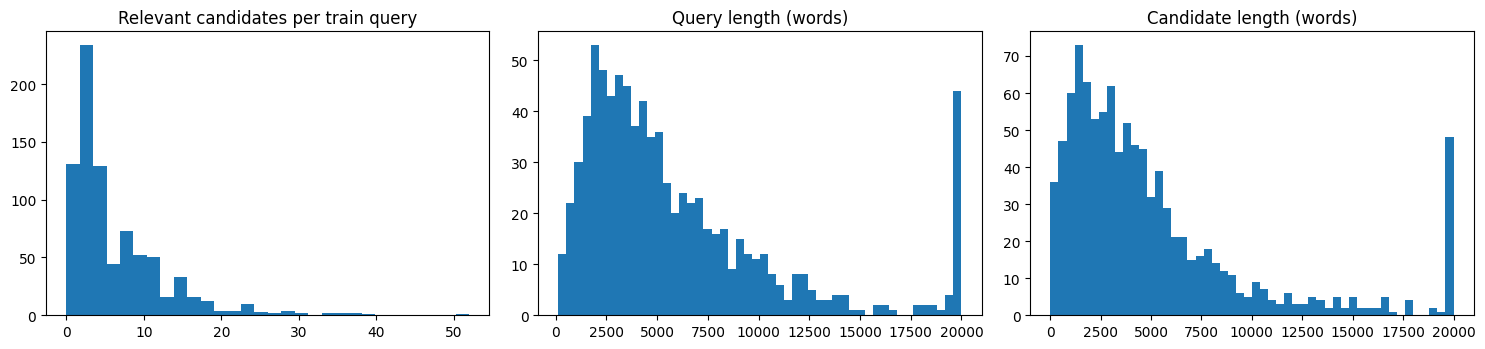

macro check: expected F1@7 of a perfect retriever = 0.6181


In [15]:
def hf(name): return hf_hub_download(HF_DATASET_REPO, f"Phase_7_PCR/{name}", repo_type="dataset", token=HF_TOKEN)
def norm(d):
    if isinstance(d, list): d = {str(x.get("id")): x for x in d}
    return {str(k): v for k, v in d.items()}
PH = re.compile(r"<[A-Z_]{2,15}>")
def txt(v):
    t = v.get("text", v) if isinstance(v, dict) else v
    t = " ".join(t) if isinstance(t, list) else str(t)
    return re.sub(r"\s+", " ", PH.sub(" ", t)).strip()        # drop <NAME>/<ORG>/<CITATION> placeholders

RAW = {}
for sp_, (qf, cf) in dict(train=("Train/train.json", "Train/train_candidates.json"),
                          dev=("Dev/dev.json", "Dev/dev_candidates.json"),
                          test=("Test/test.json", "Test/test_candidates.json")).items():
    RAW[sp_] = (norm(json.load(open(hf(qf), encoding="utf-8"))), norm(json.load(open(hf(cf), encoding="utf-8"))))

SP = {}
for sp_, (q, c) in RAW.items():
    qids, cids = sorted(q), sorted(c); cset = set(cids)
    gold = {k: {str(x) for x in q[k].get("relevant_candidates", []) if str(x) in cset} for k in qids}
    allgold = {k: len(q[k].get("relevant_candidates", [])) for k in qids}
    SP[sp_] = dict(qids=qids, cids=cids, qtext=[txt(q[k]) for k in qids], ctext=[txt(c[k]) for k in cids], gold=gold, n_gold_raw=allgold)
del RAW; gc.collect()

for s_, d in SP.items():
    ng = np.array([len(d["gold"][k]) for k in d["qids"]])
    print(f"{s_:5s} queries {len(d['qids']):5d} | pool {len(d['cids']):6d} | gold/query mean {ng.mean():.2f} median {np.median(ng):.0f} max {ng.max()} "
          f"| gold missing from pool {sum(d['n_gold_raw'].values()) - ng.sum()}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist([len(SP['train']['gold'][k]) for k in SP['train']['qids']], bins=30); ax[0].set_title("Relevant candidates per train query")
ax[1].hist(np.clip([len(t.split()) for t in SP['train']['qtext'][:1000]], 0, 20000), bins=50); ax[1].set_title("Query length (words)")
ax[2].hist(np.clip([len(t.split()) for t in SP['train']['ctext'][:1000]], 0, 20000), bins=50); ax[2].set_title("Candidate length (words)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/eda.png", dpi=150); plt.show()
print("macro check: expected F1@7 of a perfect retriever =", 
      round(2 * (lambda tp, ng: (tp / (7 * len(SP['dev']['qids']))) * (tp / ng) / ((tp / (7 * len(SP['dev']['qids']))) + (tp / ng)))
            (sum(min(7, len(g)) for g in SP['dev']['gold'].values()), sum(len(g) for g in SP['dev']['gold'].values())), 4))

### Cell 3: Tokenisation (cached), chunking, metrics

In [16]:
def _clip(t):
    if len(t) <= 2 * HC: return t, ""
    h, tl = t[:HC], t[-HC:]
    i = h.rfind(" "); h = h[:i] if i > 0 else h
    j = tl.find(" "); tl = tl[j + 1:] if j >= 0 else tl
    return h, tl
def _tok(t):
    h, tl = _clip(t); ids = tokenizer.encode(h)[1:-1]
    if tl: ids = ids + tokenizer.encode(tl)[1:-1]
    return np.asarray(ids, dtype=np.int32)
def tok_all(texts, tag):
    path = f"{OUT}/tok_{tag}_{len(texts)}_{HC}.pkl"
    if os.path.exists(path): return pickle.load(open(path, "rb"))
    with mp.get_context("fork").Pool(os.cpu_count() or 2) as pool:
        ids = list(tqdm(pool.imap(_tok, texts, chunksize=8), total=len(texts), desc=f"tokenize {tag}"))
    pickle.dump(ids, open(path, "wb")); return ids

for s_, d in SP.items():
    qi, ci = tok_all(d["qtext"], f"{s_}_q"), tok_all(d["ctext"], f"{s_}_c")
    d["qrec"] = [dict(id=k, ids=i, nw=len(t.split())) for k, i, t in zip(d["qids"], qi, d["qtext"])]
    d["crec"] = [dict(id=k, ids=i, nw=len(t.split())) for k, i, t in zip(d["cids"], ci, d["ctext"])]
print("mean tokens/doc (train pool):", np.mean([len(r["ids"]) for r in SP["train"]["crec"]]))

def get_chunks(ids, strategy, K, U=CHUNK - 1):
    n = len(ids)
    if n <= U: return [ids]
    fwd = [(i, min(i + U, n)) for i in range(0, n, U)]
    bwd = [(max(0, e - U), e) for e in range(n, 0, -U)]
    if strategy == "head": spans = fwd[:K]
    elif strategy == "tail": spans = bwd[:K][::-1]
    elif strategy == "headtail":
        hs = fwd[:K - K // 2]; ts = [s for s in bwd[:K // 2][::-1] if s[0] >= hs[-1][1]]; spans = hs + ts
    elif strategy == "uniform":
        idx = np.unique(np.linspace(0, len(fwd) - 1, min(K, len(fwd))).round().astype(int)); spans = [fwd[i] for i in idx]
    else: raise ValueError(strategy)
    return [ids[a:b] for a, b in spans]

def chunk_batch(idlists, strategy, K, Ktr=None, rng=None):
    """-> ids [N,Km,T], chunk-mask [N,Km]. Ktr: during training keep a random subset of the K chunks (chunk dropout, cheaper)."""
    allc = []
    for ids in idlists:
        ch = get_chunks(ids, strategy, K)
        if Ktr and len(ch) > Ktr:
            sel = sorted(rng.choice(len(ch), Ktr, replace=False).tolist()); ch = [ch[i] for i in sel]
        allc.append([np.concatenate([[BOS], c]).astype(np.int64) for c in ch])
    N, Km, T = len(allc), max(len(c) for c in allc), max(len(x) for c in allc for x in c)
    ids = torch.full((N, Km, T), PAD, dtype=torch.long); cm = torch.zeros(N, Km, dtype=torch.bool)
    for i, c in enumerate(allc):
        for j, x in enumerate(c): ids[i, j, :len(x)] = torch.from_numpy(x); cm[i, j] = True
    return ids, cm

# ---------------- metric: Micro-F1@7 (+ extras) ----------------
def f1_at_k(S, qids, cids, gold, k=TOPK):
    S = S.astype(np.float32).copy(); ci = {c: i for i, c in enumerate(cids)}
    for qi, q in enumerate(qids):
        if q in ci: S[qi, ci[q]] = -1e9                   # never retrieve the query itself
    order = np.argsort(-S, 1)[:, :200]; tp = ng = r100 = 0; rr = []; pq = []
    for qi, q in enumerate(qids):
        g = gold[q]
        if not g: pq.append((0, 0)); continue
        top = [cids[j] for j in order[qi, :k]]; t = len(g & set(top)); tp += t; ng += len(g); pq.append((t, len(g)))
        r100 += len(g & {cids[j] for j in order[qi, :100]})
        hit = [i for i, j in enumerate(order[qi]) if cids[j] in g]; rr.append(1 / (hit[0] + 1) if hit else 0.0)
    nq = sum(1 for q in qids if gold[q]); P = tp / (k * nq); R = tp / max(ng, 1); F = 2 * P * R / max(P + R, 1e-12)
    return dict(f1=F, p=P, r=R, r100=r100 / max(ng, 1), mrr=float(np.mean(rr)), pq=pq)
def short(m): return {k: round(v, 4) for k, v in m.items() if k != "pq"}
def recall_curve(S, qids, cids, gold, ks=(1, 3, 5, 7, 10, 20, 50, 100)):
    return [f1_at_k(S, qids, cids, gold, k=k)["r"] * (7 and 1) if False else None for k in ks]

mean tokens/doc (train pool): 3211.05


### Cell 4: BM25 baselines (also the hard-negative source and hybrid component)

In [17]:
class BM25:
    def __init__(s, dtexts, ngram=(1, 1), max_features=300000):
        s.cv = CountVectorizer(lowercase=True, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b",
                               ngram_range=ngram, min_df=2, max_features=max_features)
        s.D = s.cv.fit_transform(dtexts).tocsr().astype(np.float32)
        N = s.D.shape[0]; df = np.bincount(s.D.indices, minlength=s.D.shape[1])
        s.idf = np.log(1 + (N - df + 0.5) / (df + 0.5)).astype(np.float32)
        s.dl = np.asarray(s.D.sum(1)).ravel(); s.avg = s.dl.mean(); s.coo = s.D.tocoo()
    def scores(s, qtexts, k1=1.2, b=0.75):
        c = s.coo; data = c.data * (k1 + 1) / (c.data + k1 * (1 - b + b * s.dl[c.row] / s.avg)) * s.idf[c.col]
        W = sp.csr_matrix((data, (c.row, c.col)), shape=s.D.shape)
        Q = s.cv.transform(qtexts).tocsr().astype(np.float32); Q.data = 1 + np.log(Q.data)       # log-damped query tf
        return (Q @ W.T).toarray().astype(np.float32)

RUN_BIGRAM = False
dv = SP["dev"]; bm_rows = []
idx_uni = BM25(dv["ctext"], (1, 1))
for k1 in (0.9, 1.2, 1.8):
    for b in (0.4, 0.75, 0.9):
        m = f1_at_k(idx_uni.scores(dv["qtext"], k1, b), dv["qids"], dv["cids"], dv["gold"])
        bm_rows.append(dict(ngram="1", k1=k1, b=b, **short(m)))
if RUN_BIGRAM:
    idx_bi = BM25(dv["ctext"], (1, 2), 500000)
    m = f1_at_k(idx_bi.scores(dv["qtext"], 1.2, 0.75), dv["qids"], dv["cids"], dv["gold"]); bm_rows.append(dict(ngram="1-2", k1=1.2, b=0.75, **short(m)))
BMG = pd.DataFrame(bm_rows).sort_values("f1", ascending=False); print(BMG.to_string(index=False))
bb_ = BMG.iloc[0]; BM_CFG = dict(ngram=(1, 2) if bb_.ngram == "1-2" else (1, 1), k1=float(bb_.k1), b=float(bb_.b)); print("BM25 config:", BM_CFG)

BM = {}                                   # BM[split] = [nq, npool] BM25 score matrix
for s_ in ("train", "dev", "test"):
    p = f"{OUT}/bm25_{s_}.npy"
    if os.path.exists(p): BM[s_] = np.load(p)
    else:
        BM[s_] = BM25(SP[s_]["ctext"], BM_CFG["ngram"]).scores(SP[s_]["qtext"], BM_CFG["k1"], BM_CFG["b"]); np.save(p, BM[s_])
BM_DEV = f1_at_k(BM["dev"], dv["qids"], dv["cids"], dv["gold"]); print("BM25 dev:", short(BM_DEV))
BM_TRAIN = f1_at_k(BM["train"], SP["train"]["qids"], SP["train"]["cids"], SP["train"]["gold"]); print("BM25 train:", short(BM_TRAIN))

ngram  k1    b     f1      p      r   r100    mrr
    1 1.8 0.90 0.2212 0.2409 0.2045 0.4995 0.6332
    1 1.2 0.90 0.1923 0.2094 0.1778 0.4666 0.5848
    1 1.8 0.75 0.1901 0.2070 0.1757 0.4656 0.5776
    1 0.9 0.90 0.1690 0.1840 0.1562 0.4471 0.5099
    1 1.2 0.75 0.1556 0.1695 0.1439 0.4388 0.4933
    1 0.9 0.75 0.1390 0.1513 0.1285 0.4193 0.4286
    1 1.8 0.40 0.0912 0.0993 0.0843 0.3679 0.2946
    1 1.2 0.40 0.0767 0.0835 0.0709 0.3525 0.2527
    1 0.9 0.40 0.0689 0.0751 0.0637 0.3422 0.2189
BM25 config: {'ngram': (1, 1), 'k1': 1.8, 'b': 0.9}
BM25 dev: {'f1': 0.2212, 'p': 0.2409, 'r': 0.2045, 'r100': 0.4995, 'mrr': 0.6332}
BM25 train: {'f1': 0.1913, 'p': 0.1845, 'r': 0.1988, 'r100': 0.504, 'mrr': 0.4668}


### Cell 5: PEFT modules (LoRA, LoRMA, QLoRA-NF4, IA³, Adapter)

In [18]:
class LoRALinear(nn.Module):
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features)); s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x): return s.base(x) + (x @ s.A.t() @ s.B.t()) * s.scale

class LoRMALinear(nn.Module):             # multiplicative low-rank update: y + s*B A y
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.out_features) / math.sqrt(base.out_features)); s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x): y = s.base(x); return y + (y @ s.A.t() @ s.B.t()) * s.scale

NF4 = torch.tensor([-1.0, -0.6961928009986877, -0.5250730514526367, -0.39491748809814453, -0.28444138169288635, -0.18477343022823334,
                    -0.09105003625154495, 0.0, 0.07958029955625534, 0.16093020141506195, 0.24611230194568634, 0.33791524171829224,
                    0.44070982933044434, 0.5626170039176941, 0.7229568362236023, 1.0])
class QLoRALinear(nn.Module):
    """Frozen base weight stored as packed 4-bit NormalFloat (block-wise absmax, block 64) + optional LoRA (r>0). Dequantised on the fly."""
    def __init__(s, base, r=8, alpha=16, bs=64):
        super().__init__()
        W = base.weight.data.float(); s.shape, s.n, s.bs, s.r = tuple(W.shape), W.numel(), bs, r
        w = F.pad(W.flatten(), (0, (-s.n) % bs)).view(-1, bs); am = w.abs().amax(1, keepdim=True).clamp(min=1e-8); x = w / am
        idx = torch.empty(x.shape, dtype=torch.uint8)
        for a in range(0, x.size(0), 8192): idx[a:a + 8192] = (x[a:a + 8192].unsqueeze(-1) - NF4).abs().argmin(-1).to(torch.uint8)
        idx = idx.flatten(); idx = F.pad(idx, (0, idx.numel() % 2))
        s.register_buffer("codes", (idx[0::2] << 4) | idx[1::2]); s.register_buffer("absmax", am.half()); s.register_buffer("nf4", NF4.clone(), persistent=False)
        if r > 0:
            s.scale = alpha / r; s.A = nn.Parameter(torch.randn(r, s.shape[1]) / math.sqrt(s.shape[1])); s.B = nn.Parameter(torch.zeros(s.shape[0], r))
    def weight(s, dtype):
        idx = torch.stack([s.codes >> 4, s.codes & 15], 1).flatten()[: s.absmax.numel() * s.bs].long()
        return (s.nf4[idx].view(-1, s.bs).to(dtype) * s.absmax.to(dtype)).flatten()[: s.n].view(s.shape)
    def forward(s, x):
        y = F.linear(x, s.weight(x.dtype))
        return y + (x @ s.A.t() @ s.B.t()) * s.scale if s.r > 0 else y

class IA3Linear(nn.Module):               # learned rescaling vectors (IA^3): scale output (k,v) or input of fc2
    def __init__(s, base, mode):
        super().__init__(); s.base, s.mode = base, mode
        s.l = nn.Parameter(torch.ones(base.out_features if mode == "out" else base.in_features))
    def forward(s, x): return s.base(x * s.l) if s.mode == "in" else s.base(x) * s.l

class Adapter(nn.Module):
    def __init__(s, d, r):
        super().__init__(); s.down, s.up = nn.Linear(d, r), nn.Linear(r, d); nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x): return x + s.up(F.gelu(s.down(x)))

def wrap(module, fn, names=None, skip_names=(), skip_dirs=()):
    for n, c in list(module.named_children()):
        if n in skip_dirs: continue
        if isinstance(c, nn.Linear) and n not in skip_names and (names is None or n in names): setattr(module, n, fn(c))
        else: wrap(c, fn, names, skip_names, skip_dirs)
ATTN_T = {"q_proj", "k_proj", "v_proj", "o_proj", "q_down", "q_up", "kv_down", "kv_up", "k_rope_proj"}

### Cell 6: Retrieval encoder, similarity, losses

In [19]:
def _blk(block, x, rope, pos, mask):
    y, aux, _ = block(x, rope, pos, None, mask); return y, aux

class Backbone(nn.Module):
    """Phase-1 decoder run BIDIRECTIONALLY (padding mask only) as a text encoder; optional adapters / prompt tuning."""
    def __init__(s, lm, adapter_dim=0, prompt_len=0, grad_ckpt=True):
        super().__init__(); s.lm, s.P, s.grad_ckpt = lm, prompt_len, grad_ckpt; D = lm.cfg.d_model
        s.adapters = nn.ModuleList([Adapter(D, adapter_dim) for _ in lm.blocks]) if adapter_dim else None
        if prompt_len: s.prompt = nn.Parameter(lm.tok_emb.weight.detach()[torch.randint(0, lm.cfg.vocab_size, (prompt_len,))].float().clone())
    def forward(s, ids, mask):
        lm, P = s.lm, s.P; B, T = ids.shape; x = lm.tok_emb(ids)
        if lm.sin_emb is not None: x = x * math.sqrt(lm.cfg.d_model)
        if P:
            x = torch.cat([s.prompt.unsqueeze(0).expand(B, -1, -1).to(x.dtype), x], 1)
            mask = torch.cat([torch.ones(B, P, dtype=mask.dtype, device=mask.device), mask], 1)
        pos = torch.arange(T + P, device=ids.device)
        if lm.sin_emb is not None: x = x + lm.sin_emb.pe[pos].to(x.dtype)
        am = mask[:, None, None, :]; aux = x.new_zeros(()); use_ck = s.grad_ckpt and s.training and torch.is_grad_enabled()
        for i, b in enumerate(lm.blocks):
            if use_ck:
                if not x.requires_grad: x = x.requires_grad_(True)             # reentrant ckpt (MoE routing breaks non-reentrant)
                x, a = checkpoint(lambda t, b=b: _blk(b, t, lm.rope, pos, am), x, use_reentrant=True)
            else: x, a = _blk(b, x, lm.rope, pos, am)
            aux = aux + a
            if s.adapters is not None: x = s.adapters[i](x)
        x = lm.final_norm(x)
        return (x[:, P:] if P else x), aux

class Encoder(nn.Module):
    """ids [N,K,T] -> normalised chunk embeddings C [N,K,D] and document vector v [N,D]."""
    def __init__(s, lm, tok_pool="mean", doc_pool="mean", adapter_dim=0, prompt_len=0):
        super().__init__(); s.bb = Backbone(lm, adapter_dim, prompt_len); D = lm.cfg.d_model; s.tp, s.dp = tok_pool, doc_pool
        if doc_pool == "attn": s.att = nn.Sequential(nn.Linear(D, 256), nn.Tanh(), nn.Linear(256, 1))
    def forward(s, ids, cm):
        N, K, T = ids.shape; D = s.bb.lm.cfg.d_model; flat = ids[cm]; tm = flat != PAD
        h, aux = s.bb(flat, tm); h = h.float(); m = tm.unsqueeze(-1).float()
        if s.tp == "mean": e = (h * m).sum(1) / m.sum(1).clamp(min=1)
        elif s.tp == "bos": e = h[:, 0]
        else: e = h.masked_fill(m == 0, -1e4).max(1).values
        e = F.normalize(e, dim=-1); C = e.new_zeros(N, K, D); C[cm] = e; cmf = cm.unsqueeze(-1).float()
        if s.dp == "mean": v = (C * cmf).sum(1) / cmf.sum(1)
        elif s.dp == "attn": w = s.att(C).squeeze(-1).masked_fill(~cm, -1e4).softmax(-1).unsqueeze(-1); v = (w * C).sum(1)
        else: v = C.masked_fill(~cm.unsqueeze(-1), -1e4).max(1).values
        return F.normalize(v, dim=-1), C, aux

def sim_matrix(q, d, sim):
    """q,d = (vec[N,D], chunks[N,K,D], chunk-mask[N,K]).  cos | maxsim (chunk-level late interaction) | mix."""
    qv, qc, qm = q; dv_, dc, dm = d; out = 0
    if sim in ("cos", "mix"): out = out + qv @ dv_.t()
    if sim in ("maxsim", "mix"):
        s = torch.einsum("qkd,ljd->qlkj", qc, dc).masked_fill(~dm[None, :, None, :], -2).max(-1).values
        qf = qm[:, None, :].float(); ms = (s * qf).sum(-1) / qf.sum(-1)
        out = out + ms
    return out / (2 if sim == "mix" else 1)

def contrastive_loss(S, pos, ign, kind, tau, margin=0.2):
    """S [B,ND] cosine. pos: sampled positives; ign: other gold docs present in the batch (masked, not treated as negatives)."""
    neg = ~(pos | ign)
    if kind == "infonce":                                  # multi-positive InfoNCE: each positive vs all negatives
        L = S / tau; lse_neg = torch.logsumexp(L.masked_fill(~neg, -1e9), 1, keepdim=True)
        term = -(L - torch.logaddexp(L, lse_neg)); return (term * pos).sum() / pos.sum()
    if kind == "listwise":                                 # ListNet: softmax over the whole list vs uniform target on positives
        logp = F.log_softmax((S / tau).masked_fill(ign, -1e9), 1); t = pos.float() / pos.sum(1, keepdim=True)
        return -(t * logp.masked_fill(~pos, 0)).sum(1).mean()
    if kind == "triplet":                                  # pairwise margin vs hardest in-list negative
        hn = S.masked_fill(~neg, -2).max(1, keepdim=True).values
        return (F.relu(margin - S + hn) * pos).sum() / pos.sum()
    raise ValueError(kind)

LRS = dict(zeroshot=0, full=3e-5, partial=5e-5, lora=5e-4, lorma=5e-4, qlora=5e-4, ia3=3e-3, adapter=5e-4, prompt=1e-2, kd=3e-5, kd_control=3e-5)
def build(spec):
    lm = load_phase1(spec["variant"], pretrained=spec.get("init", "phase1") == "phase1"); m = spec["method"]; ad = pl = 0
    if spec.get("student"):
        lm.blocks = nn.ModuleList([lm.blocks[i] for i in STUDENT_KEEP]); lm.cfg = copy.copy(lm.cfg); lm.cfg.n_layers = len(STUDENT_KEEP)
    if m not in ("full", "kd", "kd_control"):
        for p in lm.parameters(): p.requires_grad = False
    if m == "partial":
        for b in lm.blocks[-4:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.final_norm.parameters(): p.requires_grad = True
    elif m == "lora":  wrap(lm.blocks, lambda b: LoRALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "lorma": wrap(lm.blocks, lambda b: LoRMALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "qlora":
        wrap(lm.blocks, lambda b: QLoRALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})      # LoRA on attention
        wrap(lm.blocks, lambda b: QLoRALinear(b, 0), None, skip_names={"router"})                      # every other linear: 4-bit frozen
    elif m == "ia3":
        wrap(lm.blocks, lambda b: IA3Linear(b, "out"), {"k_proj", "v_proj", "kv_up"}, skip_dirs={"experts", "shared"})
        wrap(lm.blocks, lambda b: IA3Linear(b, "in"), {"fc2"}, skip_dirs={"experts", "shared"})
    elif m == "adapter": ad = 64
    elif m == "prompt": pl = PROMPT_LEN
    return Encoder(lm, spec["tok_pool"], spec["doc_pool"], ad, pl).to(DEVICE)
def count_params(model):
    tot = sum(p.numel() for p in model.parameters()) + sum(b.numel() * (0.5 if b.dtype == torch.uint8 else 0) for b in model.buffers() if b.dtype == torch.uint8)
    return tot, sum(p.numel() for p in model.parameters() if p.requires_grad)

### Cell 7: Encoding / retrieval evaluation / zero-shot baseline

In [20]:
@torch.no_grad()
def encode_set(model, recs, spec, desc=None):
    model.eval(); K = spec["K"]; bs = max(1, 32 // K); N = len(recs); D = model.bb.lm.cfg.d_model
    V = torch.zeros(N, D, dtype=torch.half); Cg = torch.zeros(N, K, D, dtype=torch.half); M = torch.zeros(N, K, dtype=torch.bool)
    for a in tqdm(range(0, N, bs), desc=desc, disable=desc is None, leave=False):
        ids, cm = chunk_batch([r["ids"] for r in recs[a:a + bs]], spec["strategy"], K)
        with amp(): v, C, _ = model(ids.to(DEVICE), cm.to(DEVICE))
        k = C.size(1); V[a:a + bs] = v.half().cpu(); Cg[a:a + bs, :k] = C.half().cpu(); M[a:a + bs, :k] = cm
    return V, Cg, M

@torch.no_grad()
def score_all(Q, Dd, sim, qb=32):
    dv_, dc, dm = [x.to(DEVICE) for x in Dd]; dv_, dc = dv_.float(), dc.float(); out = []
    for a in range(0, Q[0].size(0), qb):
        q = (Q[0][a:a + qb].to(DEVICE).float(), Q[1][a:a + qb].to(DEVICE).float(), Q[2][a:a + qb].to(DEVICE))
        out.append(sim_matrix(q, (dv_, dc, dm), sim).cpu())
    return torch.cat(out).numpy()

def score_split(model, spec, qrecs, crecs, desc=None):
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); Qe = encode_set(model, qrecs, spec, desc and desc + " q"); De = encode_set(model, crecs, spec, desc and desc + " c"); te = time.time() - t0
    S = score_all(Qe, De, spec["sim"]); peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    return S, dict(ms_per_doc=te / (len(qrecs) + len(crecs)) * 1000, enc_peak_gb=peak)

def make_devsub(nq, npool):
    d = SP["dev"]; rng = np.random.RandomState(SEED); qi = sorted(rng.permutation(len(d["qids"]))[:nq])
    qids = [d["qids"][i] for i in qi]; need = set().union(*[d["gold"][q] for q in qids])
    others = [c for c in d["cids"] if c not in need]; fill = list(rng.permutation(others)[:max(0, npool - len(need))])
    cids = sorted(need | set(fill)); cmap = {c: i for i, c in enumerate(d["cids"])}
    return dict(qids=qids, cids=cids, qrec=[d["qrec"][i] for i in qi], crec=[d["crec"][cmap[c]] for c in cids], gold={q: d["gold"][q] for q in qids},
                bm=BM["dev"][np.ix_(qi, [cmap[c] for c in cids])])
DV = make_devsub(PROF["dev_q"], PROF["dev_pool"])
print("dev-sub:", len(DV["qids"]), "queries x", len(DV["cids"]), "candidates | BM25 on dev-sub:", short(f1_at_k(DV["bm"], DV["qids"], DV["cids"], DV["gold"])))

dev-sub: 118 queries x 920 candidates | BM25 on dev-sub: {'f1': 0.2312, 'p': 0.2518, 'r': 0.2138, 'r100': 0.5252, 'mrr': 0.6403}


### Cell 8: Training data structures, hard-negative samplers, resumable trainer (+ KD)

In [21]:
# ---- training structures ----
TRS = SP["train"]; cmap_tr = {c: i for i, c in enumerate(TRS["cids"])}
TR = dict(q=TRS["qrec"], c=TRS["crec"], gold=[np.array(sorted(cmap_tr[c] for c in TRS["gold"][q]), dtype=np.int64) for q in TRS["qids"]])
TR["rank"] = dict(bm25=np.argsort(-BM["train"], 1)[:, :150])             # hard negatives from BM25; "dense" is added after the zero-shot run
spec_default = dict(strategy="headtail", K=4, tok_pool="mean", doc_pool="mean", sim="cos", loss="infonce", neg="bm25", H=1, npos=1, tau=0.05, B=8, neg_lo=0, neg_hi=50)
DEFAULT_REP = dict(spec_default)
def spec_of(variant, method, **kw):
    d = dict(variant=variant, method=method, init="phase1", student=False, **DEFAULT_REP); d.update(kw); return d

def make_batch(rng, qs, spec):
    npos, H, src, gold = spec["npos"], spec["H"], spec["neg"], TR["gold"]; Np = len(TR["c"]); P, N = [], []
    for qi in qs:
        g = gold[qi]; gs = set(g.tolist()); ps = [int(x) for x in rng.choice(g, size=min(npos, len(g)), replace=False)]; ns = []
        for _ in range(H):
            s = src if src != "mix" else str(rng.choice(["bm25", "dense"]))
            cand = [] if s == "random" else [int(c) for c in TR["rank"][s][qi][spec["neg_lo"]:spec["neg_hi"]] if int(c) not in gs and int(c) not in ns]
            if cand: ns.append(int(rng.choice(cand)))
            else:
                c = int(rng.randint(Np))
                while c in gs: c = int(rng.randint(Np))
                ns.append(c)
        P.append(ps); N.append(ns)
    uniq = list(dict.fromkeys([p for ps in P for p in ps] + [n for ns in N for n in ns])); ui = {c: j for j, c in enumerate(uniq)}
    pos = torch.zeros(len(qs), len(uniq), dtype=torch.bool); ign = torch.zeros_like(pos)
    for b, qi in enumerate(qs):
        for p in P[b]: pos[b, ui[p]] = True
        for c in uniq:
            if c in set(gold[qi].tolist()) and not pos[b, ui[c]]: ign[b, ui[c]] = True
    return uniq, pos, ign

def snap(model, full):
    sd = model.state_dict()
    if full: keys = list(sd)
    else:
        tn = {n for n, p in model.named_parameters() if p.requires_grad}; keys = [k for k in sd if k in tn]
    return {k: sd[k].detach().cpu().clone() for k in keys}
def _atomic_save(obj, path): tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)
SAVE_EVERY = 40

def fit(model, name, spec, epochs, nq, kd=None, wd=0.01, resume=True):
    method, B, Ktr = spec["method"], spec["B"], PROF["Ktr"]
    qpool = [i for i in range(len(TR["q"])) if len(TR["gold"][i]) > 0]
    qsel = qpool if nq is None else [int(x) for x in np.random.RandomState(SEED).permutation(qpool)[:nq]]
    steps_ep = math.ceil(len(qsel) / B); total = epochs * steps_ep; warm = max(1, int(0.06 * total))
    bbp = [p for n, p in model.named_parameters() if n.startswith("bb.") and p.requires_grad]; hdp = [p for n, p in model.named_parameters() if not n.startswith("bb.") and p.requires_grad]
    groups = ([dict(params=bbp, base=LRS[method])] if bbp else []) + ([dict(params=hdp, base=1e-3)] if hdp else [])
    opt = torch.optim.AdamW(groups, weight_decay=wd); scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    full_snap = method in ("full", "kd", "kd_control"); aux_c = model.bb.lm.cfg.aux_loss_coef
    last_p, best_p = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_bestsd.pt"
    start_ep, start_step, gstep, best_f, hist, carry = 0, 0, 0, -1.0, [], (0.0, 0)
    if resume and os.path.exists(last_p):
        st = torch.load(last_p, map_location="cpu", weights_only=False)
        model.load_state_dict({k: v.to(DEVICE) for k, v in st["model"].items()}, strict=False); opt.load_state_dict(st["opt"])
        if st.get("scaler") and USE_SCALER: scaler.load_state_dict(st["scaler"])
        start_ep, start_step, gstep, best_f, hist, carry = st["epoch"], st["step"], st["gstep"], st["best_f"], st["hist"], (st["tl"], st["nb"]); del st; gc.collect()
        print(f"[{name}] RESUMED epoch {start_ep+1}/{epochs} step {start_step}/{steps_ep}")
    def save_last(ep, step, tl, nb):
        _atomic_save(dict(model=snap(model, full_snap), opt=opt.state_dict(), scaler=scaler.state_dict() if USE_SCALER else None,
                          epoch=ep, step=step, gstep=gstep, best_f=best_f, hist=hist, tl=tl, nb=nb), last_p)
    for ep in range(start_ep, epochs):
        model.train(); t0 = time.time(); order = np.random.RandomState(SEED + ep).permutation(len(qsel))
        first = start_step if ep == start_ep else 0; tl, nb = carry if (ep == start_ep and first > 0) else (0.0, 0)
        for st in tqdm(range(first, steps_ep), desc=f"{name} ep{ep+1}/{epochs}", leave=False):
            qs = [qsel[j] for j in order[st * B:(st + 1) * B]]; rng = np.random.RandomState(SEED * 7919 + ep * 1000 + st)
            uniq, pos, ign = make_batch(rng, qs, spec); pos, ign = pos.to(DEVICE), ign.to(DEVICE)
            qi_, qcm = chunk_batch([TR["q"][i]["ids"] for i in qs], spec["strategy"], spec["K"], Ktr, rng)
            di_, dcm = chunk_batch([TR["c"][j]["ids"] for j in uniq], spec["strategy"], spec["K"], Ktr, rng)
            with amp():
                qv, qc, aq = model(qi_.to(DEVICE), qcm.to(DEVICE)); dv_, dc, ad_ = model(di_.to(DEVICE), dcm.to(DEVICE))
            S = sim_matrix((qv, qc, qcm.to(DEVICE)), (dv_, dc, dcm.to(DEVICE)), spec["sim"]).float()
            hard = contrastive_loss(S, pos, ign, spec["loss"], spec["tau"])
            if kd is not None:                                                 # distil teacher similarities + teacher embeddings
                tq = kd["Tq"][qs].to(DEVICE).float(); td = kd["Tc"][uniq].to(DEVICE).float(); tS = tq @ td.t()
                tau = spec["tau"]; m = ~ign | pos
                lp_s = F.log_softmax((S / tau).masked_fill(~m, -1e9), 1); p_t = F.softmax((tS / tau).masked_fill(~m, -1e9), 1)
                klv = F.kl_div(lp_s, p_t, reduction="batchmean")
                cosl = 0.5 * ((1 - (qv * tq).sum(-1)).mean() + (1 - (dv_ * td).sum(-1)).mean())
                loss = kd["alpha"] * hard + (1 - kd["alpha"]) * klv + kd["beta"] * cosl
            else: loss = hard
            loss = loss + aux_c * (aq + ad_).float()
            scaler.scale(loss).backward(); tl += float(loss.detach()); nb += 1
            f = (gstep + 1) / warm if gstep < warm else 0.1 + 0.45 * (1 + math.cos(math.pi * (gstep - warm) / max(1, total - warm)))
            for g in opt.param_groups: g["lr"] = g["base"] * f
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); gstep += 1
            if gstep % SAVE_EVERY == 0 and st + 1 < steps_ep: save_last(ep, st + 1, tl, nb)
        S_dv, _ = score_split(model, spec, DV["qrec"], DV["crec"]); m = f1_at_k(S_dv, DV["qids"], DV["cids"], DV["gold"])
        hist.append(dict(epoch=ep + 1, train_loss=tl / max(1, nb), dev_f1=m["f1"], dev_r100=m["r100"], dev_mrr=m["mrr"], sec=time.time() - t0))
        print(f"[{name}] ep{ep+1} loss {tl/max(1,nb):.4f} | dev-sub F1@7 {m['f1']:.4f} R@100 {m['r100']:.3f} MRR {m['mrr']:.3f} | {time.time()-t0:.0f}s")
        if m["f1"] > best_f: best_f = m["f1"]; _atomic_save(snap(model, full_snap), best_p)
        save_last(ep + 1, 0, 0.0, 0); carry = (0.0, 0)
    best = torch.load(best_p, map_location="cpu", weights_only=False)
    model.load_state_dict({k: v.to(DEVICE) for k, v in best.items()}, strict=False); return hist, best

### Cell 9: Experiment runner (cached) + zero-shot baseline

In [22]:
RES = {}
for fn in os.listdir(RES_DIR):
    if fn.endswith(".json"): RES[fn[:-5]] = json.load(open(f"{RES_DIR}/{fn}"))
print("cached runs:", list(RES))

def load_model(name):
    m = build(RES[name]["spec"])
    if os.path.exists(RES[name]["ckpt"]): m.load_state_dict(torch.load(RES[name]["ckpt"], map_location=DEVICE), strict=False)
    return m.eval()

def run(name, spec, *, group, epochs, nq, full_eval=True, kd=None):
    if name in RES: print(f"[{name}] cached F1sub={RES[name]['f1_sub']:.4f}"); return RES[name]
    seed_all(); model = build(spec); tot, trn = count_params(model)
    print(f"\n=== {name} | total {tot/1e6:.1f}M trainable {trn/1e6:.2f}M ({100*trn/max(tot,1):.2f}%)")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); ck = f"{CKPT_DIR}/{name}.pt"
    if spec["method"] == "zeroshot": hist = []
    else: hist, best = fit(model, name, spec, epochs, nq, kd=kd); torch.save(best, ck)
    train_sec = time.time() - t0; peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    S_sub, eff = score_split(model, spec, DV["qrec"], DV["crec"]); msub = f1_at_k(S_sub, DV["qids"], DV["cids"], DV["gold"])
    out = dict(spec=spec, group=group, ckpt=ck, hist=hist, f1_sub=msub["f1"], r100_sub=msub["r100"], trainable_M=trn / 1e6, total_M=tot / 1e6, peak_gb=peak,
               train_sec=train_sec, epochs=epochs, full_eval=bool(full_eval), **eff)
    if full_eval:
        d, t = SP["dev"], SP["test"]
        S_d, eff_d = score_split(model, spec, d["qrec"], d["crec"], "dev"); md = f1_at_k(S_d, d["qids"], d["cids"], d["gold"])
        S_t, _ = score_split(model, spec, t["qrec"], t["crec"], "test")
        np.savez(f"{SC_DIR}/{name}.npz", dev=S_d.astype(np.float16), test=S_t.astype(np.float16))
        K, D = spec["K"], model.bb.lm.cfg.d_model
        out.update(dev={k: v for k, v in md.items() if k != "pq"}, f1=md["f1"], ms_per_doc=eff_d["ms_per_doc"], enc_peak_gb=eff_d["enc_peak_gb"],
                   index_mb_vec=len(d["cids"]) * D * 2 / 1e6, index_mb_chunks=len(d["cids"]) * K * D * 2 / 1e6)
        print(f"[{name}] DONE dev F1@7 {md['f1']:.4f} P {md['p']:.3f} R {md['r']:.3f} R@100 {md['r100']:.3f} | {train_sec/60:.1f} min")
    else: print(f"[{name}] DONE dev-sub F1@7 {msub['f1']:.4f} | {train_sec/60:.1f} min")
    json.dump(out, open(f"{RES_DIR}/{name}.json", "w"), indent=1); RES[name] = out
    for sfx in ("_last.pt", "_bestsd.pt"):
        p_ = f"{CKPT_DIR}/{name}{sfx}"
        if os.path.exists(p_): os.remove(p_)
    del model; gc.collect(); torch.cuda.empty_cache(); return out

# ---- zero-shot Phase-1 encoder (no fine-tuning): how much retrieval signal does pre-training give for free? ----
zs = f"Z__{BASE_VARIANT}__zeroshot"
run(zs, spec_of(BASE_VARIANT, "zeroshot"), group="base", epochs=0, nq=0, full_eval=True)
# dense hard negatives for training: encode the TRAIN split once with the zero-shot encoder
p = f"{OUT}/dense_train_{BASE_VARIANT}.npy"
if os.path.exists(p): S_tr = np.load(p)
else:
    m = load_model(zs); S_tr, _ = score_split(m, RES[zs]["spec"], SP["train"]["qrec"], SP["train"]["crec"], "train zero-shot"); np.save(p, S_tr); del m; gc.collect(); torch.cuda.empty_cache()
TR["rank"]["dense"] = np.argsort(-S_tr, 1)[:, :150]
print("zero-shot dense on train:", short(f1_at_k(S_tr, TRS["qids"], TRS["cids"], TRS["gold"])))
print("zero-shot dense on dev  :", RES[zs]["dev"], "| BM25 dev:", short(BM_DEV))

cached runs: ['Z__clean_gqa_rope_moe__zeroshot', 'D__clean_gqa_rope_moe__kd', 'B__clean_gqa_rope_moe__full']
[Z__clean_gqa_rope_moe__zeroshot] cached F1sub=0.2557
zero-shot dense on train: {'f1': 0.1516, 'p': 0.1462, 'r': 0.1575, 'r100': 0.5333, 'mrr': 0.3744}
zero-shot dense on dev  : {'f1': 0.24680377987770982, 'p': 0.2687651331719128, 'r': 0.22816032887975335, 'r100': 0.6372045220966084, 'mrr': 0.5864415669007383} | BM25 dev: {'f1': 0.2212, 'p': 0.2409, 'r': 0.2045, 'r100': 0.4995, 'mrr': 0.6332}


### Cell 10: Study A, representation / objective / negatives (full fine-tuning, small subset, dev-sub)

In [ ]:
A_OVR = {
    "base": {},
    # chunk selection / number of chunks
    "head": dict(strategy="head"), "uniform": dict(strategy="uniform"),
    "K1": dict(K=1), "K2": dict(K=2), "K8": dict(K=8),
    # token pooling and document (chunk) pooling
    "tok_bos": dict(tok_pool="bos"), "tok_max": dict(tok_pool="max"),
    "doc_attn": dict(doc_pool="attn"), "doc_max": dict(doc_pool="max"),
    # similarity
    "sim_maxsim": dict(sim="maxsim"), "sim_mix": dict(sim="mix"),
    # ranking objective
    "loss_triplet": dict(loss="triplet"), "loss_listwise": dict(loss="listwise", npos=2),
    # negatives
    "neg_inbatch": dict(H=0), "neg_random": dict(neg="random"), "neg_dense": dict(neg="dense"), "neg_mix": dict(neg="mix", H=2),
    # temperature
    "tau0.02": dict(tau=0.02), "tau0.1": dict(tau=0.1),
}
for tag, ov in A_OVR.items():
    run(f"A__{tag}", spec_of(BASE_VARIANT, "full", **ov), group="repr", epochs=PROF["ep_abl"], nq=PROF["abl_q"], full_eval=False)

GROUPS = dict(strategy=["base", "head", "uniform"], K=["K1", "K2", "base", "K8"], tok=["base", "tok_bos", "tok_max"], doc=["base", "doc_attn", "doc_max"],
              sim=["base", "sim_maxsim", "sim_mix"], loss=["base", "loss_triplet", "loss_listwise"],
              neg=["base", "neg_inbatch", "neg_random", "neg_dense", "neg_mix"], tau=["tau0.02", "base", "tau0.1"])
REP = dict(DEFAULT_REP)
for g, tags in GROUPS.items():          # factors chosen one at a time against the shared base run (dev-sub micro-F1@7)
    tags = [t for t in tags if f"A__{t}" in RES]
    best = max(tags, key=lambda t: RES[f"A__{t}"]["f1_sub"])
    if best != "base": REP.update(A_OVR[best])
print("Selected configuration:", {k: REP[k] for k in ("strategy", "K", "tok_pool", "doc_pool", "sim", "loss", "neg", "H", "npos", "tau")})
print({t: round(RES[f"A__{t}"]["f1_sub"], 4) for t in A_OVR})

def bars(names, labels, title, fn, key="f1_sub", ref=None):
    names = [n for n in names if n in RES]; v = [RES[n][key] for n in names]
    if not v: return
    fig, ax = plt.subplots(figsize=(max(5, .9 * len(v) + 2), 3.6)); ax.bar(range(len(v)), v)
    for i, x in enumerate(v): ax.text(i, x, f"{x:.3f}", ha="center", va="bottom", fontsize=8)
    if ref is not None: ax.axhline(ref, c="r", ls="--", lw=.8, label="BM25"); ax.legend()
    ax.set_xticks(range(len(v))); ax.set_xticklabels([l for n, l in zip(names, labels)], rotation=35, ha="right"); ax.set_ylim(max(0, min(v) - .05), max(v) + .04)
    ax.set_ylabel(key); ax.set_title(title); plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/{fn}.png", dpi=150); plt.show()
bm_sub = f1_at_k(DV["bm"], DV["qids"], DV["cids"], DV["gold"])["f1"]
for g, tags in GROUPS.items(): bars([f"A__{t}" for t in tags], tags, f"Study A: {g} (dev-sub micro-F1@7)", f"A_{g}", ref=bm_sub)

### Cell 11: Study B, adaptation techniques on the base architecture

In [ ]:
TECH = ["full", "partial", "lora", "lorma", "qlora", "ia3", "adapter", "prompt"]   # LoRMA is compulsory; trim this list to save time
for m in TECH:
    run(f"B__{BASE_VARIANT}__{m}", spec_of(BASE_VARIANT, m, **{k: REP[k] for k in REP}), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
# Optional transfer control (random init, NOT a pretrained model; analysis only, never submitted):
RUN_SCRATCH = False
if RUN_SCRATCH:
    run(f"B__{BASE_VARIANT}__scratch", spec_of(BASE_VARIANT, "full", init="scratch", **REP), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)

In [24]:
REP = dict(DEFAULT_REP)
def top7_ids(S, qids, cids):
    S = S.astype(np.float32).copy(); ci = {c: i for i, c in enumerate(cids)}
    for qi, q in enumerate(qids):
        if q in ci: S[qi, ci[q]] = -1e9                      # never retrieve the query itself
    return {q: [cids[j] for j in np.argsort(-S[qi])[:TOPK]] for qi, q in enumerate(qids)}

def z(S): return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-6)

def write_sub(tag, S_test):
    t = SP["test"]; pred = top7_ids(S_test, t["qids"], t["cids"]); pool = set(t["cids"])
    assert set(pred) == set(t["qids"]) and all(len(v) == TOPK and len(set(v)) == TOPK and set(v) <= pool for v in pred.values()), "format check failed"
    d = f"{OUT}/sub_{tag}"; os.makedirs(d, exist_ok=True)
    json.dump(pred, open(f"{d}/prediction.json", "w"))
    zp = f"/kaggle/working/submission_{tag}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as zf: zf.write(f"{d}/prediction.json", arcname="prediction.json")
    print(f"  saved {zp}"); return zp

def resolve_name(variant, method):
    """Map (variant, method) -> run name. KD runs are stored as D__<variant>__kd / kd_control, the rest as B__<variant>__<method>."""
    for pre in ("B", "D", "A", "Z"):
        n = f"{pre}__{variant}__{method}"
        if n in RES and RES[n].get("full_eval"): return n
    return None

def export(variant, method, hybrid=True, make_final=False):
    """Save submission zip(s) for one finished run. Returns (name, dev F1 of the chosen option, zip path) or None."""
    name = resolve_name(variant, method)
    if name is None:
        print(f"[skip] {variant}/{method}: not finished or has no test scores (finished: {[n for n in RES if RES[n].get('full_eval')]})"); return None
    sc = np.load(f"{SC_DIR}/{name}.npz"); S_dev, S_test = sc["dev"].astype(np.float32), sc["test"].astype(np.float32); d = SP["dev"]
    f_dense = f1_at_k(S_dev, d["qids"], d["cids"], d["gold"])["f1"]; print(f"{name}: dev micro-F1@7 dense {f_dense:.4f}")
    best_f, best_zip = f_dense, write_sub(name, S_test)
    if hybrid and "BM" in globals():
        ws = np.linspace(0, 1, 11); curve = [f1_at_k((1 - w) * z(S_dev) + w * z(BM["dev"]), d["qids"], d["cids"], d["gold"])["f1"] for w in ws]
        w = ws[int(np.argmax(curve))]; print(f"  hybrid w={w:.1f}: dev F1@7 {max(curve):.4f}")
        zp = write_sub(f"{name}_hybrid", (1 - w) * z(S_test) + w * z(BM["test"]))
        if max(curve) > best_f: best_f, best_zip = max(curve), zp
    if make_final:
        shutil.copy(best_zip, "/kaggle/working/submission.zip"); print(f"  FINAL -> {best_zip} -> /kaggle/working/submission.zip")
    return name, best_f, best_zip

def export_many(variant, methods, make_final=True):
    """methods: list like ["full", "kd", "lorma"]. If variant is a list, exports every variant x method combination."""
    variants = [variant] if isinstance(variant, str) else variant
    out = [r for v in variants for m in methods if (r := export(v, m))]
    if make_final and out:
        name, f, zp = max(out, key=lambda r: r[1]); shutil.copy(zp, "/kaggle/working/submission.zip")
        print(f"\nsubmission.zip <- {name} (dev F1@7 {f:.4f})")
    return out

def export_all(make_final=True):
    """Export every finished run that has test scores (all variants, all methods)."""
    out = [r for n in [k for k in RES if RES[k].get("full_eval")]
           if (r := export(RES[n]["spec"]["variant"], RES[n]["spec"]["method"]))]
    if make_final and out:
        name, f, zp = max(out, key=lambda r: r[1]); shutil.copy(zp, "/kaggle/working/submission.zip")
        print(f"\nsubmission.zip <- {name} (dev F1@7 {f:.4f})")
    return out

In [36]:
REP = dict(DEFAULT_REP)
run(f"B__{BASE_VARIANT}__full", spec_of(BASE_VARIANT, "full", **{k: REP[k] for k in REP}), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
export_many(BASE_VARIANT, ["full"])


=== B__clean_gqa_rope_moe__full | total 152.1M trainable 152.13M (100.00%)
[B__clean_gqa_rope_moe__full] RESUMED epoch 2/4 step 17/103


B__clean_gqa_rope_moe__full ep2/4:   0%|          | 0/86 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep2 loss 1.5942 | dev-sub F1@7 0.3002 R@100 0.720 MRR 0.675 | 252s


B__clean_gqa_rope_moe__full ep3/4:   0%|          | 0/103 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep3 loss 1.5468 | dev-sub F1@7 0.3035 R@100 0.713 MRR 0.679 | 292s


B__clean_gqa_rope_moe__full ep4/4:   0%|          | 0/103 [00:00<?, ?it/s]

... (3 outputs left out)

test q:   0%|          | 0/30 [00:00<?, ?it/s]

test c:   0%|          | 0/216 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] DONE dev F1@7 0.2924 P 0.318 R 0.270 R@100 0.694 | 14.2 min
B__clean_gqa_rope_moe__full: dev micro-F1@7 dense 0.2935
  saved /kaggle/working/submission_B__clean_gqa_rope_moe__full.zip
  hybrid w=0.2: dev F1@7 0.3180
  saved /kaggle/working/submission_B__clean_gqa_rope_moe__full_hybrid.zip

submission.zip <- B__clean_gqa_rope_moe__full (dev F1@7 0.3180)


[('B__clean_gqa_rope_moe__full',
  0.31795441912173433,
  '/kaggle/working/submission_B__clean_gqa_rope_moe__full_hybrid.zip')]

### Cell 12: Study C, all four Phase-1 architectures

In [ ]:
ARCH_METHODS = ["full"]            # add "lorma" to also compare the parameter-efficient method on every architecture
for v in VARIANTS:
    for m in ARCH_METHODS:
        run(f"B__{v}__{m}", spec_of(v, m, **REP), group="arch", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)

### Cell 13: Study D, knowledge distillation (teacher = best full-size fine-tune, student = 4 of 16 blocks)

In [25]:
cands = [n for n in RES if n.startswith(f"B__{BASE_VARIANT}__") and RES[n].get("full_eval") and RES[n]["spec"]["method"] == "full"]
teacher = max(cands, key=lambda n: RES[n]["f1"]) if cands else f"B__{BASE_VARIANT}__full"; print("teacher:", teacher)
tsp = RES[teacher]["spec"]; stu = dict(tsp, method="kd", student=True)
kd_name, ctl_name = f"D__{BASE_VARIANT}__kd", f"D__{BASE_VARIANT}__kd_control"

if kd_name not in RES:
    cache_p = f"{OUT}/teacher_{teacher}.pt"
    if os.path.exists(cache_p): c = torch.load(cache_p)
    else:
        t0 = time.time(); tm_ = load_model(teacher)
        Tq = encode_set(tm_, TR["q"], tsp, "teacher q")[0]; Tc = encode_set(tm_, TR["c"], tsp, "teacher pool")[0]
        c = dict(Tq=Tq, Tc=Tc, sec=time.time() - t0); torch.save(c, cache_p); del tm_; gc.collect(); torch.cuda.empty_cache()
    run(kd_name, stu, group="kd", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True, kd=dict(Tq=c["Tq"], Tc=c["Tc"], alpha=0.5, beta=0.5))
    # RES[kd_name]["teacher_cache_sec"] = c["sec"]; json.dump(RES[kd_name], open(f"{RES_DIR}/{kd_name}.json", "w"), indent=1)
# # no-KD control: same pruned student, same data, plain contrastive loss
# run(ctl_name, dict(stu, method="kd_control"), group="kd", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
# for n in (teacher, kd_name, ctl_name):
#     r = RES[n]; print(f"{n:42s} F1 {r['f1']:.4f} | params {r['total_M']:.1f}M | {r['ms_per_doc']:.1f} ms/doc | enc peak {r['enc_peak_gb']:.2f} GB | train peak {r['peak_gb']:.1f} GB | {r['train_sec']/60:.0f} min")
export_many(kd_name, ["kd"])

teacher: B__clean_gqa_rope_moe__full
[skip] D__clean_gqa_rope_moe__kd/kd: not finished or has no test scores (finished: ['Z__clean_gqa_rope_moe__zeroshot', 'D__clean_gqa_rope_moe__kd', 'B__clean_gqa_rope_moe__full'])


[]

In [28]:
# "partial", "lora", "lorma", "qlora", "ia3", "adapter", "prompt"
 # "mla_sin_moe"]
run(f"B__{BASE_VARIANT}__qlora", spec_of(BASE_VARIANT, "qlora", **{k: REP[k] for k in REP}), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
export_many(BASE_VARIANT, ["qlora"])
BASE_VARIANT = "gqa_sin_moe"
run(f"B__{BASE_VARIANT}__lora", spec_of(BASE_VARIANT, "lora", **{k: REP[k] for k in REP}), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
export_many(BASE_VARIANT, ["lora"])
BASE_VARIANT = "mla_rope_moe"
run(f"B__{BASE_VARIANT}__lorma", spec_of(BASE_VARIANT, "lorma", **{k: REP[k] for k in REP}), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
export_many(BASE_VARIANT, ["lorma"])
BASE_VARIANT = "mla_sin_moe"
run(f"B__{BASE_VARIANT}__prompt", spec_of(BASE_VARIANT, "prompt", **{k: REP[k] for k in REP}), group="tech", epochs=PROF["ep_tech"], nq=PROF["tech_q"], full_eval=True)
export_many(BASE_VARIANT, ["prompt"])



=== B__clean_gqa_rope_moe__qlora | total 56.0M trainable 0.64M (1.14%)


B__clean_gqa_rope_moe__qlora ep1/4:   0%|          | 0/103 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__qlora] ep1 loss 1.9480 | dev-sub F1@7 0.2913 R@100 0.682 MRR 0.647 | 328s


B__clean_gqa_rope_moe__qlora ep2/4:   0%|          | 0/103 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__qlora] ep2 loss 1.6954 | dev-sub F1@7 0.2991 R@100 0.713 MRR 0.660 | 332s


B__clean_gqa_rope_moe__qlora ep3/4:   0%|          | 0/103 [00:00<?, ?it/s]

... (44 outputs left out)

test q:   0%|          | 0/30 [00:00<?, ?it/s]

test c:   0%|          | 0/216 [00:00<?, ?it/s]

[B__mla_sin_moe__prompt] DONE dev F1@7 0.2034 P 0.222 R 0.188 R@100 0.602 | 19.9 min
B__mla_sin_moe__prompt: dev micro-F1@7 dense 0.2023
  saved /kaggle/working/submission_B__mla_sin_moe__prompt.zip
  hybrid w=0.3: dev F1@7 0.2802
  saved /kaggle/working/submission_B__mla_sin_moe__prompt_hybrid.zip

submission.zip <- B__mla_sin_moe__prompt (dev F1@7 0.2802)


[('B__mla_sin_moe__prompt',
  0.2801556420233463,
  '/kaggle/working/submission_B__mla_sin_moe__prompt_hybrid.zip')]